# AP 155 Lab Exercise
---
## Exercise 9: Minimization

_Instructions_: 
- **Problem 1**
    - Figure: Generate a $1\times2$ showing the two functions and minima markings solved using golden-search
    - Discussion: What happens if a number other than the golden ratio is used to perform the golden section search algorithm? What did you have to do to obtain the maximum?
- **Problem 2**
    - Figure: Plot of $U$ vs $N$ (for a minimum of 20 $N$ points). Compare points calculated from gradient descent with the analytical $U_\text{thom}$ (see link in problem).
    - Discussion: In a single sentence, describe what gradient descent does. How does the parameter $\gamma$ matter? 
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: 
- _Student No._: 20XX-XXXXX
- _Section_: THR-TX-X

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

![](golden_ratio.png)

The plot displays the function curve with extrema at $x \approx 0.76$ (local minimum), $x = 2$ (local maximum), and $x = 4$ (global minimum). The right plot verifies these critical points through the first derivative $\phi'(x)$, where the zeroes (orange markers) perfectly align with the extrema of $\phi(x)$. This confirms that the derivative vanishes precisely where the function changes slope, validating the accuracy of the search algorithm.

The golden-section search uses  the golden ratio  because its self-similarity property ensures that lowering the bracket preserves one interior evaluation point from the previous step, restricting updates to a single new function evaluation per iteration. Using any other ratio doubles the calculations per iteration, using unnecessary memory in the process. To locate a function's maximum using this method, just apply the method to the negative of the function ($-\phi(x)$).

![](thomson_energy_comparison.png)

The plot shows the compared calculated energies, where the calculated energies are close to theoretical values at low N but diverge beyond $N \approx 40$ due to the high density of local minima and saddle points, which can confuse the algorithm in suboptimal configurations.  

Gradient descent is an iterative optimization algorithm that updates parameter values toward the opposite direction of the function's gradient to locate a local minimum. The parameter $\gamma$ (learning rate) controls the magnitude of each step taken along the gradient. If $\gamma$ is too large, the algorithm can overshoot the minimum or diverge, while if it is too small, convergence becomes ineffeciently slow.



---
## Section 2: Code

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import math

rng = np.random.default_rng(24601)

### Problem 1: Min-maxxing with golden-search

Consider the following equation,

$$
\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4. \tag{1}
$$

- Plot $\phi$ across some domain $x$ (you choose the domain). Visually inspect the plot and record initial estimates for all local minima and local maxima within the interval.
- Implement the Golden-Section Search algorithm (see Section $3$, you may copy it into your code below) to find function minima within a given bracket $[a, b]$ to a specified tolerance. Use your algorithm to locate the precise coordinates $(x^*, \phi(x^*))$ of all local minima and local maxima of Eq. $(1)$.
- **[REPORT FIGURE 1]** Generate a single figure containing a $1 \times 2$ array of subplots:
    - Left Subplot: Plot $\phi(x)$ versus $x$. Overlay and label all identified local minima and maxima using distinct markers.
    - Right Subplot: Plot the analytical first derivative $\phi'(x)$ versus $x$. Mark the zero-crossing points that correspond to the extrema found on the left plot.

In [247]:
# add the `golden` function here
def gRSearch(func, x0, x1, kmax=1000, tol=0.000001): # takes input of the target function, boundary values, the maximum nuber of iterations and the tolerance for w
  gr = 0.5 * (1 + np.sqrt(5))
  xnew = None
  for k in range(1, kmax):
    x2 = x0 + (x1 - x0) / (gr + 1)
    x3 = x0 + (x1 - x0) * gr / (gr + 1)
    if func(x3) < func(x2):
      x0 = x2
    else:
      x1 = x3
    xnew = (x0 + x1) / 2
    xdiff = abs(x1 - x0)
    if abs(xdiff) < tol:
      break
  return xnew

# takes input of the target function, boundary values, the maximum number of iterations, and the tolerance for the final state.
# Two new test x values are made with a formula using the golden ratio as shown above. These values' function results are compared
# and new boundaries will be dictated depending on which x value is higher. The value with the lower function result will be labeled
# as a new boundary while maintaing the previous unchanged boundary then the processes iterates itself. This occurs until the result 
# has a significantly lower difference with previous iterations. The final answer is the average of the resulting boundary values.
  


# add docstrings and comments explaining what the function does

Extrema (x*, phi(x*)):
  x = 0.7500, phi(x) = -3.4180
  x = 2.0000, phi(x) = -0.0000
  x = 4.0000, phi(x) = -12.0000


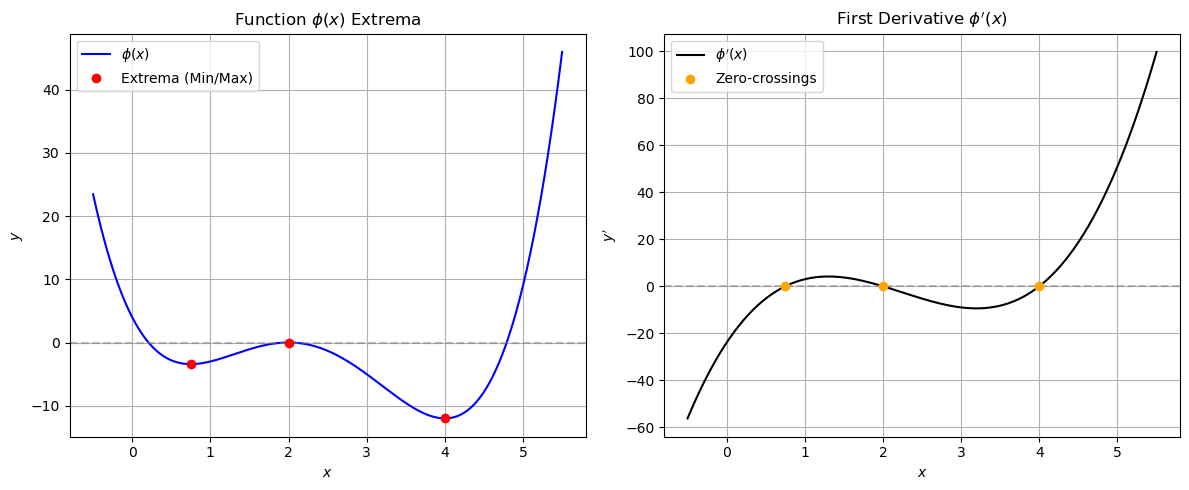

In [251]:
# define Eq. (1)

def phi(x):
  return x**4 - 9 * x**3 + 25 * x**2 - 24 * x + 4


def d_phi(x):
  return 4 * x**3 - 27 * x**2 + 50 * x - 24

ranges = [
    (0.0, 1.5),  
    (1.5, 3.0),  
    (3.0, 5.0),  
]


x_min1 = gRSearch(phi, 0.0, 1.5)
x_max = gRSearch(lambda x: -phi(x), 1.5, 3.0)  #negative since it is a maximum
x_min2 = gRSearch(phi, 3.0, 5.0)

exX= [x_min1, x_max, x_min2]
exY = [phi(x) for x in extrema_x]

print(f"Extrema (x*, phi(x*)):")

for ex, ey in zip(exX, exY):
  print(f"  x = {ex:.4f}, phi(x) = {ey:.4f}")

x_vals = np.linspace(-0.5, 5.5, 400)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))


ax1.plot(x_vals, phi(x_vals), label=r"$\phi(x)$", color="blue")
ax1.scatter(
    exX,
    exY,
    color="red",
    zorder=5,
    label="Extrema (Min/Max)",
)
ax1.set_title("Function $\phi(x)$ Extrema")
ax1.set_xlabel("$x$")
ax1.set_ylabel("$y$")
ax1.axhline(0, color="gray", linestyle="--", alpha=0.5)
ax1.grid(True)
ax1.legend()


ax2.plot(x_vals, d_phi(x_vals), label=r"$\phi'(x)$", color="black")
ax2.scatter(
    exX,
    [d_phi(x) for x in extrema_x],
    color="orange",
    zorder=5,
    label="Zero-crossings",
)
ax2.set_title("First Derivative $\phi'(x)$")
ax2.set_xlabel("$x$")
ax2.set_ylabel("$y'$")
ax2.axhline(0, color="gray", linestyle="--", alpha=0.5)
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.savefig('golden_ratio.png', dpi=300)
plt.show()




# report figure 1

#### Problem 1 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---
### Problem 2: Thomson problem with gradient descent ([Wikipedia link](https://en.wikipedia.org/wiki/Thomson_problem))

The goal of the Thomson problem is to determine the minimum electrostatic potential energy configuration given $N$ electrons constrained to the surface of a unit sphere. The electrons repel each other with a force given by Coulomb's law. The total electrostatic potential energy of each $N$-electron configuration may then be expressed as the sum of all pair-wise interaction energies:
$$ U(N) = \sum_{i<j} \frac{1}{r_{ij}}. \tag{2}$$
In context of minimization, we call Eq. $(2)$ our **cost function** or **loss function**. Here, we use simplified units of $e=1$ and $k=1/4\pi\epsilon_0=1$ (the Coulomb constant) without loss of generality.

- Complete the codes below. Add docstrings and comments to all functions.
- Create a 1D array `sphe_params` of initial particle positions in spherical coordinates (random $\theta$, $\phi$, BUT constrained to the surface of a unit sphere i.e. $r=1$).
- Minimize loss function $U(N)$ using gradient descent and `sphe_params` as your initial guess (see Section 3, you may the codes `termcrit`, `gradient`, and `descent` into your code below). Your output should be a 1D array similar to `sphe_params` but the positions that minimizes the potential.
- **[REPORT FIGURE 2]** Plot of $U$ vs $N$. Compare points calculated from gradient descent with the analytical $U_\text{thom}$ (see link in problem).
    - (Optional) Use 3D plotting in Matplotlib to show the geometry for $N=60$ configuration. What does it look like? What is its corresponding net electrostatic potential?

In [240]:

def termcrit(xolds,xnews): # Computes the total relative error between the old and new parameter states
    to check for convergence.
    errs = np.abs((xnews - xolds)/xnews)
    return np.sum(errs)

def gradient(phi,xs,h=1.e-6): # calculates numerical gradient
    n = xs.size
    phi0 = phi(xs)
    Xph = (xs*np.ones((n,n))).T + np.identity(n)*h
    grad = (phi(Xph) - phi0)/h
    return grad



def descent(phi, gradient, xolds, gamma=0.15, kmax=200, tol=1.e-8): # Performs iterative gradient descent optimization 

    for k in range(1, kmax):
        grad = gradient(phi, xolds)
        xnews = xolds - gamma * grad
        err = termcrit(xolds, xnews)

        if err < tol:
            print(f"Converged at iteration {k}")
            return xnews
            
        xolds = np.copy(xnews)
        
    print(f"Reached max iterations ({kmax}).")
    return xnews

# An initial guess is made and is subtracted by the gradient at that point  multiplied by a scaling factor gamma, which determines the step size.  
# The process is done iteratively until the difference between iterations is minimal below tolerance. The final x value is the root.

    
# add docstrings and comments explaining what the functions do

In [241]:
# COMPLETE THIS FUNCTION
def spherical_to_cartesian(sphe_params, R0=1.0):
    """
    sphe_params: Nx2 array of particle positions in spherical coords
    R0: radius set to 1 (unit circle)
    
    returns Nx3 array of particle positions in cartesian coords
    """
    N = len(sphe_params) // 2
    thetas = sphe_params[:N]
    phis = sphe_params[N:]
    
    x = R0*np.sin(sphe_params[:N])*np.cos(sphe_params[N:]) # calculate x from R0, thetas, phis (use np funcs)
    y = R0*np.sin(sphe_params[:N])*np.sin(sphe_params[N:]) # calculate y from R0, thetas, phis (use np funcs)
    z = R0*np.cos(sphe_params[:N])# calculate z from R0, thetas, phis (use np funcs)
    
    return np.column_stack((x, y, z))


def compute_dist(sphe_params, R0=1.0):
    """
    sphe_params: Nx2 array of particle positions in spherical coords
    R0: radius set to 1 (unit circle)

    returns distance matrix where ij is the distance between ith and jth particle
    """
    pos = spherical_to_cartesian(sphe_params, R0)
    diff = pos[:, np.newaxis, :] - pos[np.newaxis, :, :]
    dist_matrix = np.linalg.norm(diff, axis=-1)
    return dist_matrix

def electrostatic_potential(sphe_params, R0=1.0):
    """
    sphe_params: Nx2 array of particle positions in spherical coords
    R0: radius set to 1 (unit circle)

    returns total electrostatic potential
    """
    # Guard: handle 2D matrix input passed from gradient()
    if sphe_params.ndim == 2:
        return np.array([electrostatic_potential(sphe_params[:, j], R0) for j in range(sphe_params.shape[1])])

    d_matrix = compute_dist(sphe_params, R0)
    
    # calculate N dynamically from the input array length
    N_local = len(sphe_params) // 2
    i_upper, j_upper = np.triu_indices(N_local, k=1)
    distances = d_matrix[i_upper, j_upper]
        
    return np.sum(1.0 / distances)

Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached max iterations (800).
Reached ma

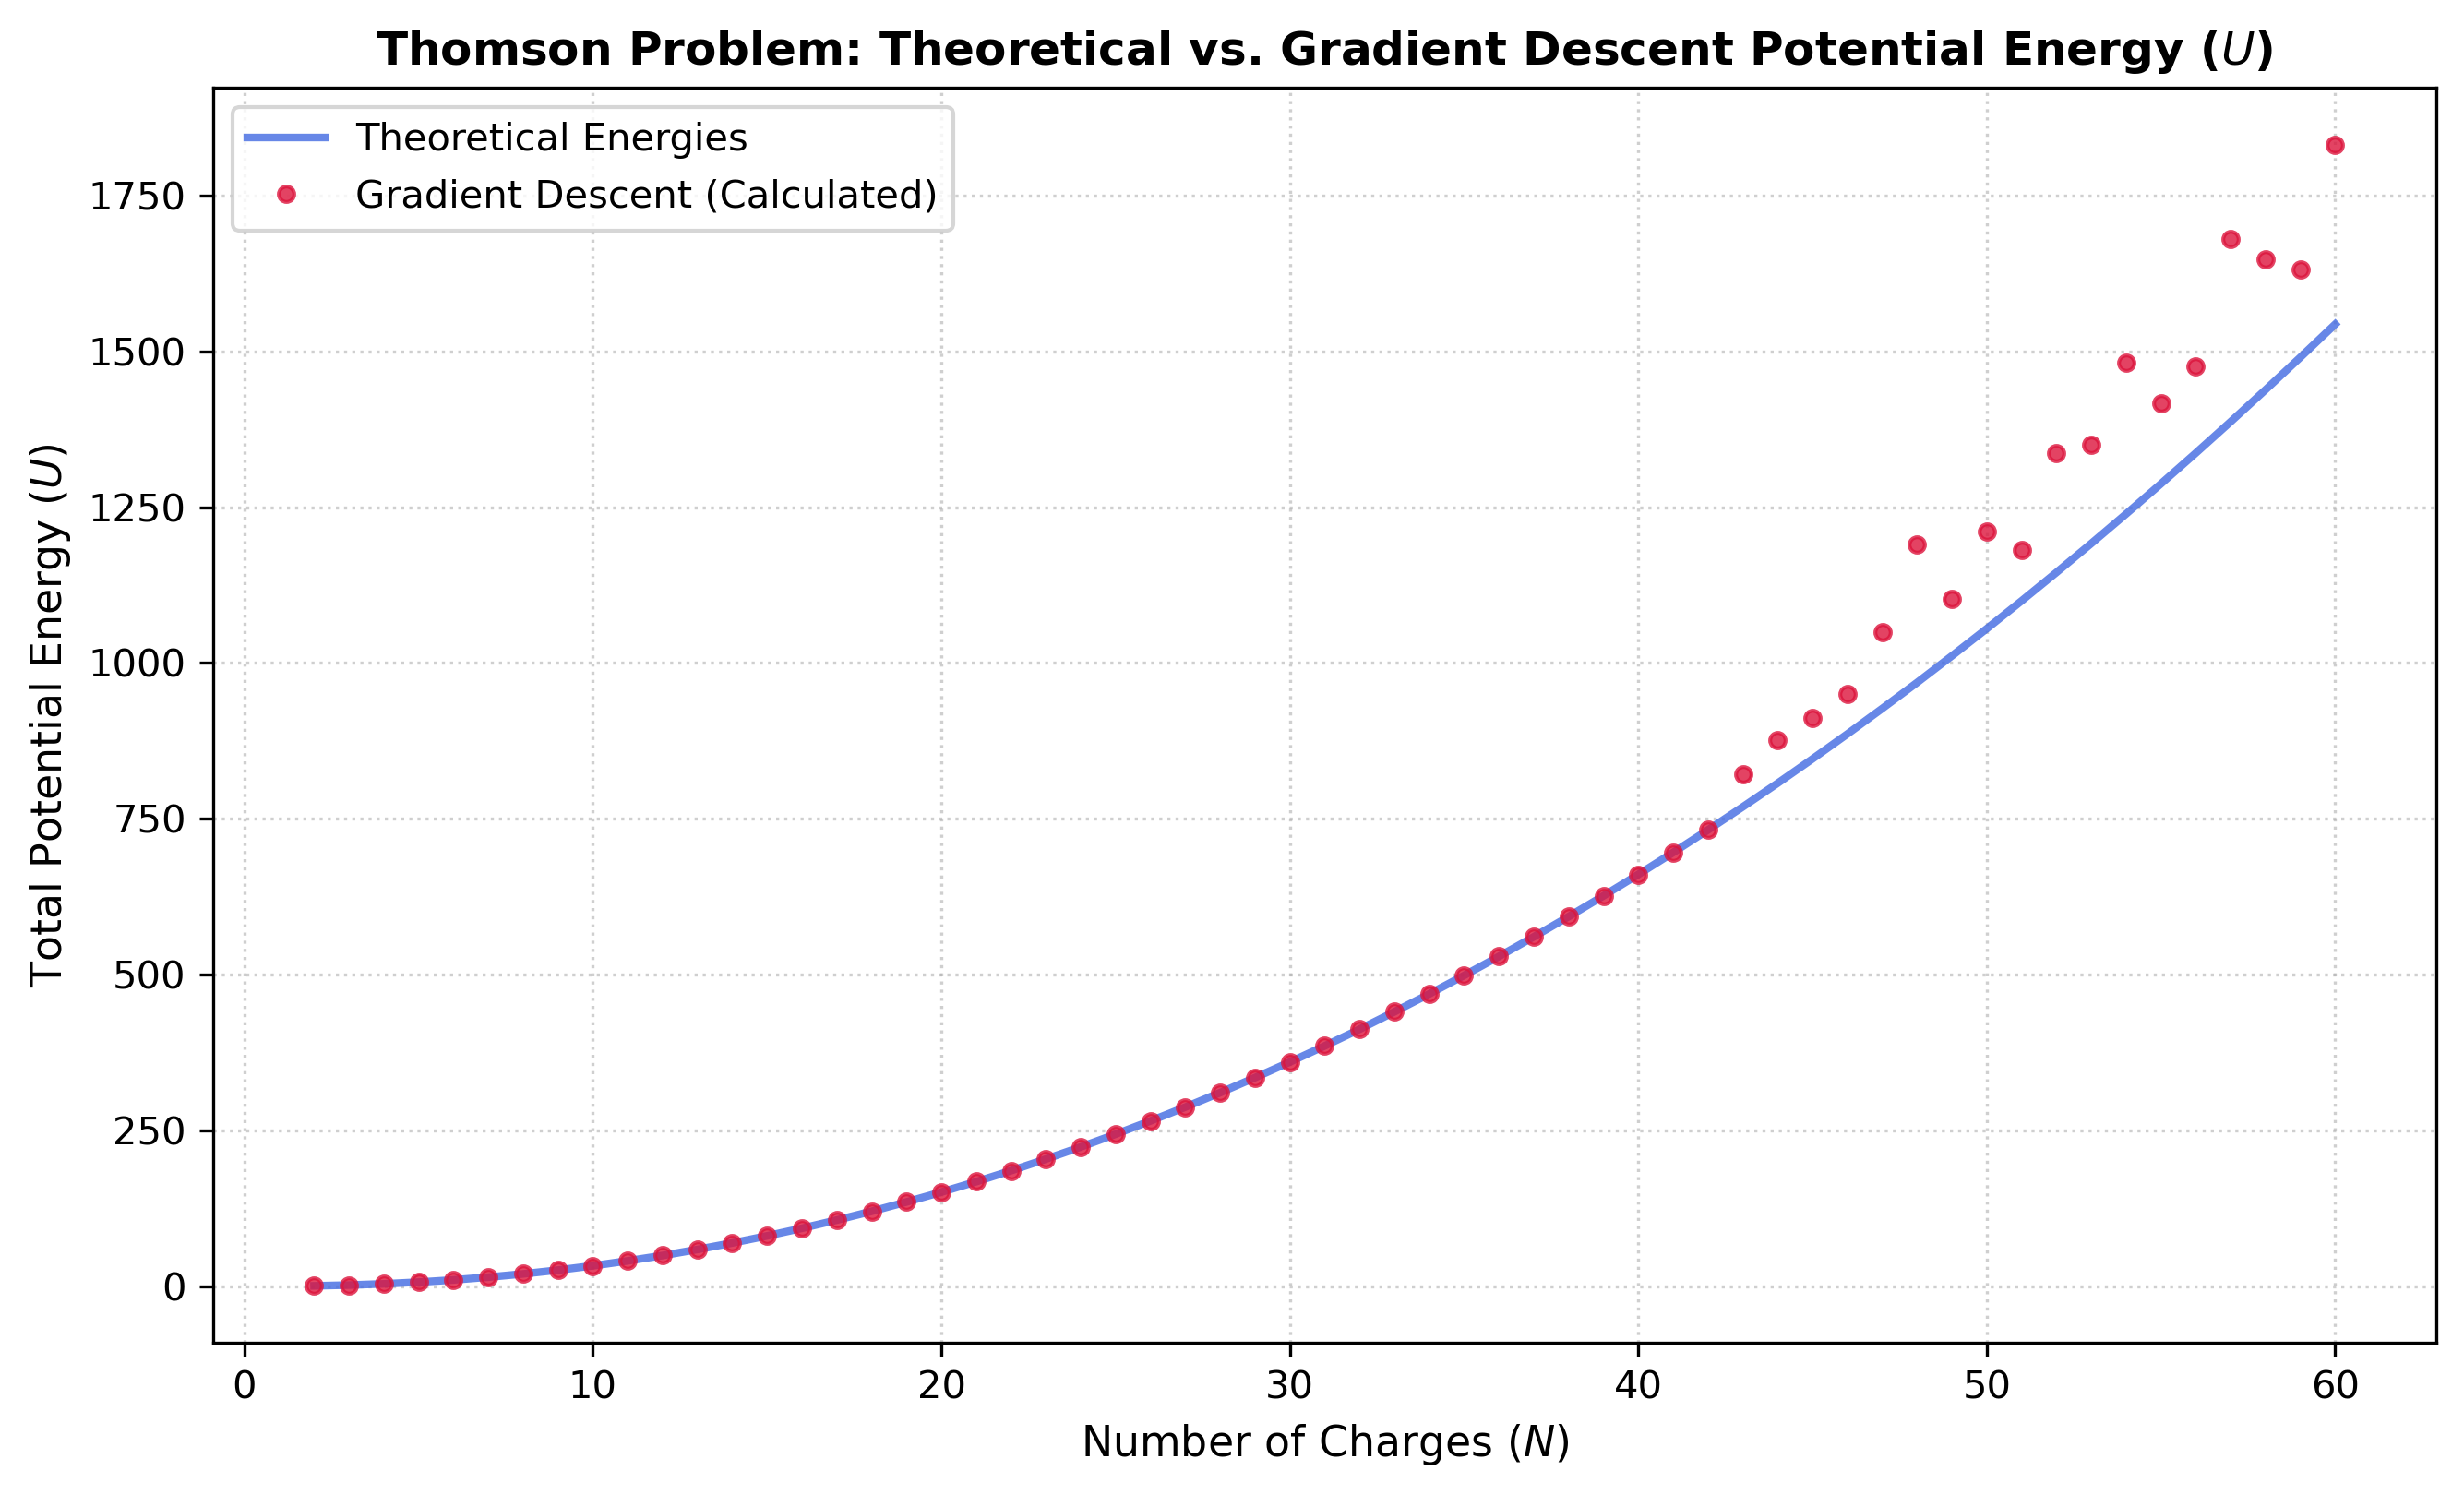

In [248]:
# from N=2 up to 20 (or more), generate the optmized positions and calculate the corresponding minimized potential energies
# for each N, always initialize a random array of positions of N particles



# Initialize random generator for reproducibility
rng = np.random.default_rng(24601)

N_min = 2
N_max = 60
n_values = list(range(N_min, N_max + 1))

calculated_u_thom = []



for N in n_values:
    init_theta = rng.uniform(0, np.pi, N)
    init_phi = rng.uniform(0, 2 * np.pi, N)
    xolds = np.hstack((init_theta, init_phi))
    
    # Run gradient descent optimization
    xnews = descent(electrostatic_potential, gradient, xolds, gamma=0.03, kmax=800, tol=1.0e-7)
    
    # Calculate and store the minimized potential energy
    min_potential = electrostatic_potential(xnews)
    calculated_u_thom.append(min_potential)
    
# --- Theoretical List ---
n = np.linspace(2, 60, 59)
u_thom = [
    0.500000000, 1.732050808, 3.674234614, 6.474691495, 9.985281374,
    14.452977414, 19.675287861, 25.759986531, 32.716949460, 40.596450510,
    49.165253058, 58.853230612, 69.306363297, 80.670244114, 92.911655302,
    106.050404829, 120.084467447, 135.089467557, 150.881568334, 167.641622399,
    185.287536149, 203.930190663, 223.347074052, 243.812760299, 265.133326317,
    287.302615033, 310.491542358, 334.634439920, 359.603945904, 385.530838063,
    412.261274651, 440.204057448, 468.904853281, 498.569872491, 529.122408375,
    560.618887731, 593.038503566, 626.389009017, 660.675278835, 695.916744342,
    732.078107544, 769.190846459, 807.174263085, 846.188401061, 886.167113639,
    927.059270680, 968.713455344, 1011.557182654, 1055.182314726, 1099.819290319,
    1145.418964319, 1191.922290416, 1239.361474729, 1287.772720783, 1337.094945276,
    1387.383229253, 1438.618250640, 1490.773335279, 1543.830400976
]

# --- REPORT FIGURE: Compare Theoretical vs. Gradient Descent ---
plt.figure(figsize=(9, 5.5), dpi=300)

plt.plot(n, u_thom, '-', color='royalblue', label='Theoretical Energies', linewidth=2, alpha=0.8)
plt.plot(n_values, calculated_u_thom, 'o', color='crimson', label='Gradient Descent (Calculated)', markersize=4, alpha=0.8)

plt.title('Thomson Problem: Theoretical vs. Gradient Descent Potential Energy ($U$)', fontsize=12, fontweight='bold')
plt.xlabel('Number of Charges ($N$)', fontsize=11)
plt.ylabel('Total Potential Energy ($U$)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()

plt.savefig('thomson_energy_comparison.png', dpi=300, bbox_inches='tight')

plt.show()



# add axes labels and legends

In [245]:
# OPTIONAL
# for 3d plotting of N=60 (it might take a minute to process)

N = 60
init_theta = None # insert code here
init_phi = None # insert code here
xolds = np.hstack((init_theta, init_phi))
xnews = None # insert code here

# calculate the spherical coordinates of N particles that minimizes
pos = spherical_to_cartesian(xnews)
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

# Draw wireframe sphere
u = np.linspace(0, 2 * np.pi, 30)
v = np.linspace(0, np.pi, 30)
x_sp = np.outer(np.cos(u), np.sin(v))
y_sp = np.outer(np.sin(u), np.sin(v))
z_sp = np.outer(np.ones(np.size(u)), np.cos(v))
ax.plot_wireframe(x_sp, y_sp, z_sp, color='lightgrey', alpha=0.3)

# Plot charge positions
ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2], color='crimson', s=60, edgecolors='k', depthshade=True)

ax.set_box_aspect([1, 1, 1])
ax.set_title('3D view of N=60 that minimizes U', fontsize=14)
plt.show()


TypeError: object of type 'NoneType' has no len()

#### Problem 2 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---
## Section 3: Notes

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Golden search (minimization tool)

In [2]:
from math import sqrt

def golden(phi, x0, x1, kmax=200, tol=1.e-8):
    varphi = 0.5*(1 + sqrt(5))
    
    for k in range(1,kmax):
        x2 = x0 + (x1-x0)/(varphi+1)
        x3 = x0 + (x1-x0)*varphi/(varphi+1)
        
        if phi(x3) < phi(x2):
            x0 = x2
        else:
            x1 = x3
    
        xnew = (x0+x1)/2
        xdiff = abs(x1-x0)
    
        if abs(xdiff) < tol:
            break
    else:
        xnew = None
    
    return xnew

#### Example: 

The Buckingham potential is an approximate representation of the potential
energy of interaction between atoms in a solid or gas as a function of the distance $r$ between them:
$$ V(r) = V_0 \left[\left(\frac{\sigma}{r}\right)^6 - e^{-r/\sigma}\right].$$

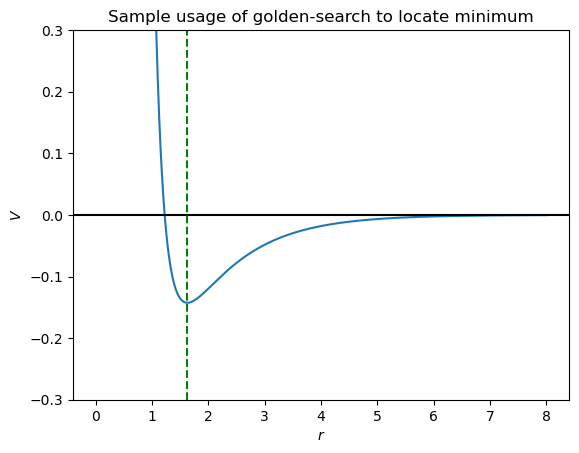

In [27]:
sigma = 1

def V(r, V0=1):
    return V0 * ((sigma / r)**6 - np.exp(-r/sigma))

rlist = np.linspace(1e-3, 8, 1000)
rmin = golden(V, 1.1, 2, kmax=200, tol=1e-8)
plt.plot(rlist, V(rlist))
plt.ylim(-.3, .3)
plt.axhline(0, c='k')
plt.axvline(rmin, c='g', ls='--')
plt.xlabel(r'$r$')
plt.ylabel(r'$V$')
plt.title('Sample usage of golden-search to locate minimum')
plt.show()

### Gradient descent (minimization tool)

In [20]:
def termcrit(xolds,xnews):
    errs = np.abs((xnews - xolds)/xnews)
    return np.sum(errs)

def gradient(phi,xs,h=1.e-6):
    n = xs.size
    phi0 = phi(xs)
    Xph = (xs*np.ones((n,n))).T + np.identity(n)*h
    grad = (phi(Xph) - phi0)/h
    return grad

def descent(phi, gradient, xolds, gamma=0.15, kmax=200, tol=1.e-8):
    for k in range(1, kmax):
        grad = gradient(phi, xolds)
        xnews = xolds - gamma * grad
        err = termcrit(xolds, xnews)

        if err < tol:
            print(f"Converged at iteration {k}")
            return xnews
            
        xolds = np.copy(xnews)
        
    print(f"Reached max iterations ({kmax}).")
    return xnews

Converged at iteration 50


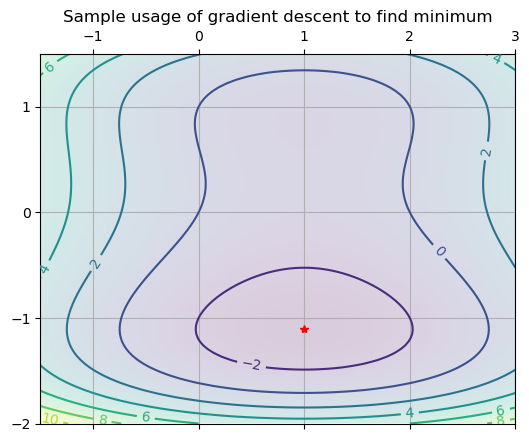

In [26]:
def sample_phi(xs):
    x0, x1 = xs
    return x0**2 - 2*x0 + x1**4 - 2*x1**2 + x1

x = np.linspace(-1.5, 3.0, 100)
y = np.linspace(-2, 1.5, 100)
X, Y = np.meshgrid(x, y)
output = sample_phi(np.array([X, Y]))

xolds = np.array([2.,0.25])
xnews = descent(sample_phi, gradient, xolds)

fig, ax = plt.subplots(dpi=100)

my_extent = [min(x), max(x), min(y), max(y)]
ax.matshow(output, origin="lower", extent=my_extent, alpha=0.2)
ax.plot(*xnews, 'r*')
ax.set_title("Sample usage of gradient descent to find minimum")
csx = ax.contour(X, Y, output)
ax.clabel(csx)
ax.grid(True)
ax.set_aspect('equal')


fig.show()

### Powell's algorithm (minimization tool)

In [29]:
def powell(phi,xolds,nreset=4,cycmax=200,tol=1.e-8):
    n = xolds.size
    for icyc in range(cycmax):
        xnews = np.copy(xolds)
    
        if icyc%nreset==0:
            U = np.identity(n)
        for k in range(n):
            ga = golden(lambda g: phi(xnews+g*U[:,k]),-10.,+10.)
            xnews += ga*U[:,k]
        U[:,:-1] = U[:,1:]
        U[:,-1] = xnews - xolds
        ga = golden(lambda g: phi(xolds+g*U[:,-1]),-10.,+10.)
        xolds += ga*U[:,-1]
        
        err = termcrit(xolds,xnews)
        # print(icyc, xnews, err, phi(xnews))
        if err < tol:
            break
    else:
        xnews = None
    return xnews

[ 1.00000002 -1.10715988]


Text(0.5, 1.0, "Sample usage of powell's algorithm to find minimum")

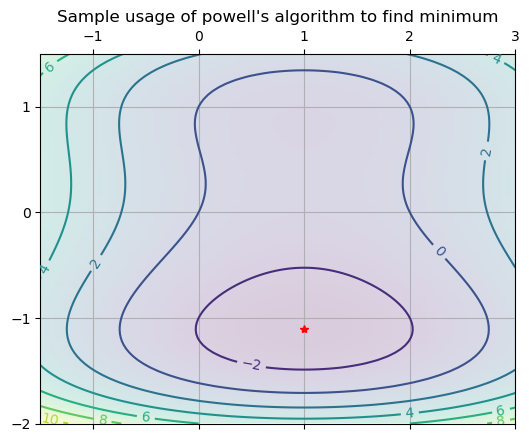

In [30]:
def phi_func(xs):
    x0,x1 = xs
    return x0**2 - 2*x0 + x1**4 - 2*x1**2 + x1

x0 = np.linspace(-1.5, 3.0, 100)
x1 = np.linspace(-2, 1.5, 100)
X0, X1 = np.meshgrid(x, y)
output = phi_func(np.array([X0, X1]))

fig, ax = plt.subplots(1, 1, dpi=100)

xolds = np.array([2.,0.25])
xnews = powell(sample_phi, xolds); print(xnews)
ax.plot(*xnews, 'r*')

my_extent = [min(x0), max(x0), min(x1), max(x1)]
ax.matshow(output, origin="lower", extent=my_extent, alpha=0.2)
csx = ax.contour(X0, X1, output)
ax.clabel(csx)
ax.grid(True)
ax.set_aspect('equal')
ax.set_title("Sample usage of powell's algorithm to find minimum")

### Plotting subplots

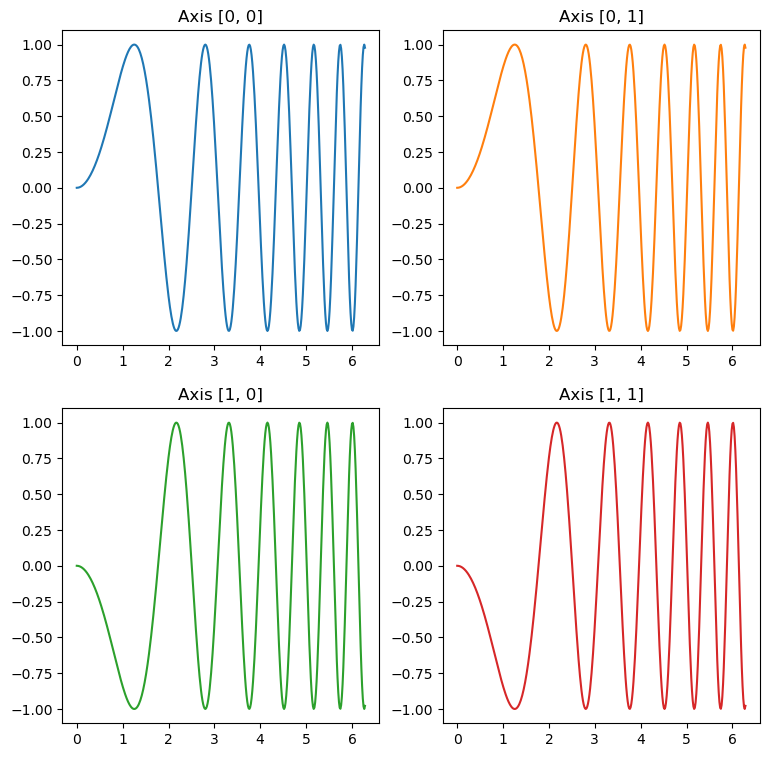

In [3]:
#sample incomplete 2 by 2 plot 

x = np.linspace(0, 2 * np.pi, 400)
y = np.sin(x ** 2)

fig, axs = plt.subplots(2, 2, figsize = (9,9))

axs[0, 0].plot(x, y)
axs[0, 0].set_title('Axis [0, 0]')

axs[0, 1].plot(x, y, 'tab:orange')
axs[0, 1].set_title('Axis [0, 1]')

axs[1, 0].plot(x, -y, 'tab:green')
axs[1, 0].set_title('Axis [1, 0]')

axs[1, 1].plot(x, -y, 'tab:red')
axs[1, 1].set_title('Axis [1, 1]')

fig.show()

### Others

(Optional) Visualizing the vector field.
This is not required to get the method running, but it's a nice way for us to realize that we are indeed working with vector fields. Also, the mesh-forming syntax here will be useful for our succeeding activities.

In [7]:
def nonlin_func(x):
    # From Eq. 5.72 in Gezerlis, annotating Code 5.5
    #* Note: we expect the input and output of the function
    #  to be BOTH vectors. If x is a k-dimensional vector,
    #  then f(x) should also return a k-dimensional vector.  
    x0, x1 = x[0], x[1]

    # This is the same as defining f0 and f1 separately. We
    # just casted the output directly into the array
    return np.array([
        (x0**2) - (2*x0) + (x1**4) - (2*x1**2) + (x1),
        (x0**2) + (x0) + (2*x1**3) - (2*x1**2) - (1.5*x1) - 0.05   
    ])

x_test = np.array([0.5, 0.6])
print(nonlin_func(x_test))

[-0.7404 -0.488 ]


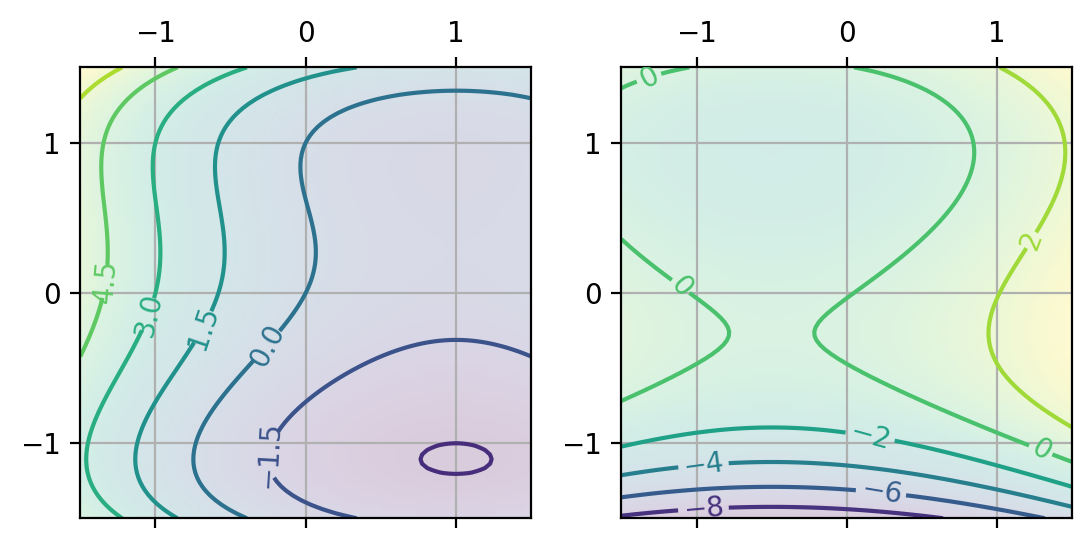

In [19]:
x = np.linspace(-1.5, 1.5, 100)
y = np.linspace(-1.5, 1.5, 100)
X, Y = np.meshgrid(x, y)
output = nonlin_func(np.array([X, Y]))

fig, axs = plt.subplots(1, 2, dpi=200)

my_extent = [min(x), max(x), min(y), max(y)]
axs[0].matshow(output[0], origin="lower", extent=my_extent, alpha=0.2)
csx = axs[0].contour(X, Y, output[0])
axs[0].clabel(csx)

axs[1].matshow(output[1], origin="lower", extent=my_extent, alpha=0.2)
csy = axs[1].contour(X, Y, output[1])
axs[1].clabel(csy)

for ax in axs:
    ax.grid(True)

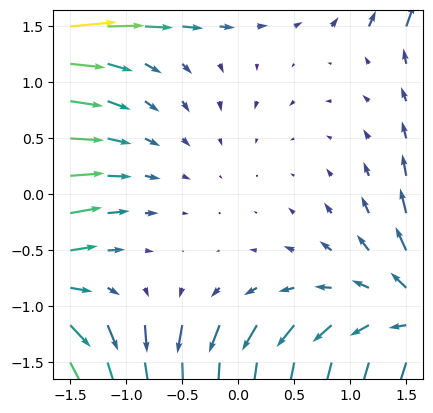

In [9]:
x = np.linspace(-1.5, 1.5, 10)
y = np.linspace(-1.5, 1.5, 10)
X, Y = np.meshgrid(x, y)
output = nonlin_func(np.array([X, Y]))

fig, ax = plt.subplots(1, dpi=100)

mag = np.sqrt(output[0]**2 + np.sqrt(output[1]**2))
ax.quiver(X, Y, output[0], output[1], mag)
ax.grid(alpha=0.2)
ax.set_aspect("equal")

In [11]:
import numpy as np

def backsub(U,bs):
    """
    Input:
        * U matrix
        * bs known vector
    Output: solve column vector using back substitution
    """
    n = bs.size
    xs = np.zeros(n)
    for i in reversed(range(n)):
        xs[i] = (bs[i] - U[i,i+1:]@xs[i+1:])/U[i,i]
    return xs

def gauelimpivot(inA,inbs):
    """
    Input:
        * inA matrix
        * inbs known vector
    Output: solve column vector with gaussian elimination
    """
    A = np.copy(inA)
    bs = np.copy(inbs)
    n = bs.size
    for j in range(n-1):
        k = np.argmax(np.abs(A[j:,j])) + j
        if k != j:
            A[j,:], A[k,:] = A[k,:], A[j,:].copy()
            bs[j], bs[k] = bs[k], bs[j]
    
        for i in range(j+1,n):
            coeff = A[i,j]/A[j,j]
            A[i,j:] -= coeff*A[j,j:]
            bs[i] -= coeff*bs[j]
            
    xs = backsub(A,bs)
    return xs

def termcrit(xolds,xnews):
    """
    Input:
        * xolds older estimates
        * xnews newest estimates
    Output: solve termination criterion with numpy
    """
    errs = np.abs((xnews - xolds)/xnews)
    return np.sum(errs)

def fs(xs):
    """
    Input:
        * xs tuple input
    Output: scalar outputs from two functions given one set of input
    """
    x0, x1 = xs
    f0 = x0**2 - 2*x0 + x1**4 - 2*x1**2 + x1
    f1 = x0**2 + x0 + 2*x1**3 - 2*x1**2 - 1.5*x1 - 0.05
    return np.array([f0,f1])

def jacobian(fs,xs,h=1.e-4):
    """
    Input:
        * fs : function of system of equations taking 1d array `xs` and returns 1d array of func values
        * xs : 1d array representing the eval point
        * h : float, optional 
    
    Output: builds jacobian matrix Jf and array containing values evaluated at xs
    """
    n = xs.size
    iden = np.identity(n)
    Jf = np.zeros((n,n))
    fs0 = fs(xs)
    for j in range(n):
        fs1 = fs(xs+iden[:,j]*h)
        Jf[:,j] = (fs1 - fs0)/h
    return Jf, fs0

def multinewton(fs,jacobian,xolds,kmax=200,tol=1.e-8):
    """
    Input:
        * fs : function of system of equations taking 1d array `xs` and returns 1d array of func values
        * jacobian : calcs the jacobian
        * xolds : 1d array containing the initial guess vector
        * kmax : no of iterations
        * tol : tolerance for convergence
    
    Output: 1d array of the approximate root vector if converged
    """
    for k in range(1,kmax):
        Jf, fsxolds = jacobian(fs, xolds)
        xnews = xolds + gauelimpivot(Jf, -fsxolds)
        err = termcrit(xolds, xnews)
        print(k, xnews, err)
        if err < tol:
            break
        
        xolds = np.copy(xnews)
    else:
        xnews = None
    return xnews

if __name__ == '__main__':
    xolds = np.array([1.,1.])
    xnews = multinewton(fs, jacobian, xolds)
    print(xnews); print(fs(xnews))

1 [0.68327197 1.99963178] 0.9634539886260238
2 [0.38286992 1.62816875] 1.0127537609121247
3 [0.56358881 1.4144802 ] 0.4717294772974023
4 [0.5900614  1.32693341] 0.11084089956296016
5 [0.59215596 1.3126421 ] 0.014424613090514531
6 [0.59218625 1.31228241] 0.00032525133774643014
7 [0.59218627 1.31228212] 2.5249741194196077e-07
8 [0.59218627 1.31228212] 4.335881037833639e-11
[0.59218627 1.31228212]
[3.97459843e-14 2.77972090e-14]
